# Hodgkin-Huxley Neuron Simulator
### Notebook 03 — Phase Portrait & Nullclines

The phase portrait is a geometric representation of the neuron's dynamics.
Instead of plotting voltage against time, we plot two state variables
against each other simultaneously — revealing the shape of the trajectory
in state space.

We will:
1. Plot the phase portrait of V vs n during an action potential
2. Compute and plot the nullclines — the curves where dV/dt = 0 and dn/dt = 0
3. Identify the fixed point — the resting state where all derivatives are zero
4. Show how the limit cycle emerges above the bifurcation threshold

## What is a phase portrait?

In notebook 01 we plotted V(t) — voltage as a function of time.
Here we plot V vs n directly, ignoring time.

Each point on the curve represents the state of the neuron at one instant.
The full curve shows the trajectory the neuron follows through state space.
A closed loop means rhythmic firing — the neuron keeps cycling through
the same states repeatedly. This closed loop is called a limit cycle.

The nullclines are two special curves:
- V-nullcline: all points where dV/dt = 0 (voltage is momentarily not changing)
- n-nullcline: all points where dn/dt = 0 (n gate is momentarily not changing)
Where they intersect is the fixed point — the resting state.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

plt.rcParams['figure.figsize'] = (8, 7)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# --- Rate functions ---
def alpha_m(V): return 0.1 * (25 - V) / (np.exp((25 - V) / 10) - 1)
def beta_m(V):  return 4.0 * np.exp(-V / 18)
def alpha_h(V): return 0.07 * np.exp(-V / 20)
def beta_h(V):  return 1.0 / (np.exp((30 - V) / 10) + 1)
def alpha_n(V): return 0.01 * (10 - V) / (np.exp((10 - V) / 10) - 1)
def beta_n(V):  return 0.125 * np.exp(-V / 80)

# --- Parameters ---
C_m=1.0; g_Na=120.0; g_K=36.0; g_L=0.3
E_Na=115.0; E_K=-12.0; E_L=10.6

# --- Model ---
def hodgkin_huxley(t, state, I_ext):
    V, m, h, n = state
    I_Na = g_Na * m**3 * h * (V - E_Na)
    I_K  = g_K  * n**4      * (V - E_K)
    I_L  = g_L              * (V - E_L)
    dV = (I_ext - I_Na - I_K - I_L) / C_m
    dm = alpha_m(V)*(1-m) - beta_m(V)*m
    dh = alpha_h(V)*(1-h) - beta_h(V)*h
    dn = alpha_n(V)*(1-n) - beta_n(V)*n
    return [dV, dm, dh, dn]

# --- Initial conditions ---
V0 = 0.0
m0 = alpha_m(V0)/(alpha_m(V0)+beta_m(V0))
h0 = alpha_h(V0)/(alpha_h(V0)+beta_h(V0))
n0 = alpha_n(V0)/(alpha_n(V0)+beta_n(V0))
initial_state = [V0, m0, h0, n0]

print("model ready")

model ready


## Running the simulation

We simulate 300ms to let the neuron settle into its rhythmic firing pattern,
then extract the V and n trajectories to plot against each other.

In [2]:
I_ext = 10.0
t_end = 300

t_eval = np.linspace(0, t_end, t_end * 100)
sol = solve_ivp(
    hodgkin_huxley,
    [0, t_end],
    initial_state,
    t_eval=t_eval,
    args=(I_ext,),
    method='RK45',
    max_step=0.05
)

V_trace = sol.y[0]
n_trace = sol.y[3]

# discard first 100ms to remove onset transient
# only plot the settled rhythmic portion
mask = sol.t > 100
V_plot = V_trace[mask]
n_plot = n_trace[mask]

print(f"trajectory length: {len(V_plot)} points")

trajectory length: 20000 points


## Computing the nullclines

The V-nullcline is found by setting dV/dt = 0 and solving for n at each V.
This requires assuming m and h are at their steady-state values for each V
(a standard simplification called the quasi-steady-state approximation).

The n-nullcline is simply the steady-state value of n at each V:
n_inf(V) = alpha_n(V) / (alpha_n(V) + beta_n(V))

In [3]:
V_range = np.linspace(-20, 120, 500)

# n-nullcline: steady state of n at each V
n_nullcline = alpha_n(V_range) / (alpha_n(V_range) + beta_n(V_range))

# V-nullcline: solve dV/dt = 0 for n at each V
# dV/dt = 0 means I_ext = I_Na + I_K + I_L
# rearranging for n: n^4 = (I_ext - I_Na_ss - I_L) / (g_K * (V - E_K))
m_ss = alpha_m(V_range) / (alpha_m(V_range) + beta_m(V_range))
h_ss = alpha_h(V_range) / (alpha_h(V_range) + beta_h(V_range))

I_Na_ss = g_Na * m_ss**3 * h_ss * (V_range - E_Na)
I_L_ss  = g_L * (V_range - E_L)

numerator = I_ext - I_Na_ss - I_L_ss
denominator = g_K * (V_range - E_K)

n4 = numerator / denominator
# only valid where n4 is between 0 and 1
valid = (n4 >= 0) & (n4 <= 1)
V_nullcline_V = V_range[valid]
V_nullcline_n = n4[valid] ** 0.25

print("nullclines computed")

nullclines computed


## The phase portrait

The purple curve is the limit cycle — the trajectory the neuron follows
during rhythmic firing. The green dashed curve is the n-nullcline.
The orange dashed curve is the V-nullcline. Their intersection is the
fixed point — the resting state the neuron returns to when stimulation stops.

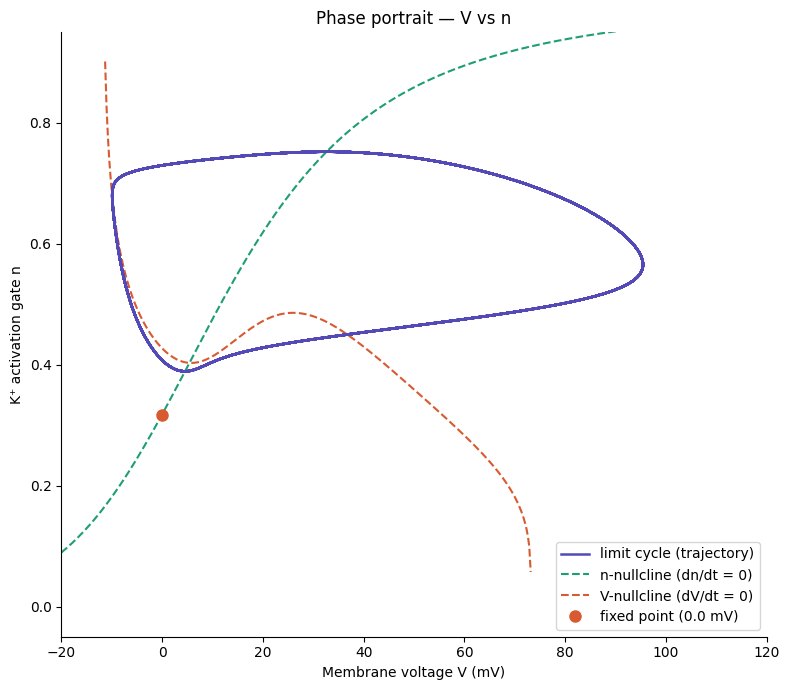

In [4]:
fig, ax = plt.subplots()

# limit cycle
ax.plot(V_plot, n_plot, color='#534AB7', linewidth=1.8,
        label='limit cycle (trajectory)', zorder=3)

# n-nullcline
ax.plot(V_range, n_nullcline, color='#1D9E75', linewidth=1.5,
        linestyle='--', label='n-nullcline (dn/dt = 0)')

# V-nullcline
ax.plot(V_nullcline_V, V_nullcline_n, color='#D85A30', linewidth=1.5,
        linestyle='--', label='V-nullcline (dV/dt = 0)')

# fixed point — intersection near resting state
ax.plot(V0, n0, 'o', color='#D85A30', markersize=8,
        label=f'fixed point ({V0:.1f} mV)', zorder=5)

ax.set_xlabel('Membrane voltage V (mV)')
ax.set_ylabel('K⁺ activation gate n')
ax.set_title('Phase portrait — V vs n')
ax.legend(fontsize=10)
ax.set_xlim(-20, 120)
ax.set_ylim(-0.05, 0.95)
plt.tight_layout()
plt.savefig('../figures/phase_portrait.png', dpi=150)
plt.show()